# Random Forest Classification and Feature Importance

## Project Introduction

The goal of this project is to classify breast tumors as **malignant (target 0)** or **benign (target 1)** using the Breast Cancer Wisconsin dataset and a Random Forest classifier.

The notebook explores the dataset, splits it into training and test sets, compares model hyperparameters with cross-validation, evaluates classification performance, and interprets feature importance. Because this is a medical classification example, malignant-class recall and false negatives are important alongside overall accuracy.

The results are for educational analysis only and should not be used as a clinical diagnostic tool.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score , GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    recall_score
)


## 1. Import Libraries

The libraries used in this notebook support data handling (`pandas`), plotting (`matplotlib`), model training (`RandomForestClassifier`), model selection (`GridSearchCV`, `StratifiedKFold`, and `cross_val_score`), and evaluation (`accuracy_score`, `recall_score`, the classification report, confusion matrix, and permutation importance).

Using separate tools for training, validation, evaluation, and interpretation helps us assess both predictive performance and which features the fitted model relies on.

In [2]:
data = load_breast_cancer()

X = pd.DataFrame(data.data , columns=data.feature_names)
y = pd.Series(data.target , name="target")

X.head()


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [3]:
X.tail()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,1.1760,1.256,7.673,158.70,0.010300,0.02891,0.05198,0.02454,0.01114,0.004239,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,0.7655,2.463,5.203,99.04,0.005769,0.02423,0.03950,0.01678,0.01898,0.002498,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,0.4564,1.075,3.425,48.55,0.005903,0.03731,0.04730,0.01557,0.01318,0.003892,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,0.7260,1.595,5.772,86.22,0.006522,0.06158,0.07117,0.01664,0.02324,0.006185,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400
568,7.76,24.54,47.92,181.0,0.05263,0.04362,0.00000,0.00000,0.1587,0.05884,0.3857,1.428,2.548,19.15,0.007189,0.00466,0.00000,0.00000,0.02676,0.002783,9.456,30.37,59.16,268.6,0.08996,0.06444,0.0000,0.0000,0.2871,0.07039


In [4]:
y.head(10)

0    0
1    0
2    0
3    0
4    0
5    0
6    0
7    0
8    0
9    0
Name: target, dtype: int64

In [5]:
y.tail(10)

559    1
560    1
561    1
562    0
563    0
564    0
565    0
566    0
567    0
568    1
Name: target, dtype: int64

In [6]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [7]:
X.shape

(569, 30)

In [8]:
y.value_counts()

target
1    357
0    212
Name: count, dtype: int64

In [9]:
X.isnull().sum()

mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
dtype: int64

## 2. Load and Explore the Dataset

The Breast Cancer Wisconsin dataset contains measurements of cell nuclei and a binary target. In this dataset, **target 0 is malignant** and **target 1 is benign**.

The exploration cells inspect the feature names and data types, dataset dimensions, target distribution, and missing values. These checks help confirm what the model will learn from and whether any basic data-quality issues need attention.

The training split contains 455 samples: 170 malignant cases (class 0) and 285 benign cases (class 1). This means benign cases are more frequent in the training data, so class distribution should be considered when evaluating the model.

In [10]:
X_train , X_test , y_train , y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

## 3. Splitting the Dataset

We split the dataset into training and testing sets so that final evaluation uses examples that were not used to fit the model or select its hyperparameters.

- **X_train / y_train:** Features and target labels used for model fitting and cross-validation.
- **X_test / y_test:** Held-out features and labels used for final evaluation.
- **test_size=0.2:** Assigns 20% of the 569 samples (114 samples) to the test set and 80% to training.
- **random_state=42:** Makes the split reproducible.
- **stratify=y:** Preserves the class proportions as closely as possible in both sets.

Cross-validation is performed on the training set. The held-out test set should be used for the final assessment, not repeatedly used to choose hyperparameters.

In [11]:
model = RandomForestClassifier(
    random_state=42,
    class_weight="balanced"
)

param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [5, 10, 15, None],
    "min_samples_split": [2],
    "min_samples_leaf": [1],
    "max_features": ["sqrt", "log2"]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grd = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    cv=cv,
    scoring="recall_macro",
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

grd.fit(X_train, y_train)

print("Best Parameters:")
print(grd.best_params_)

print("Best CV Macro Recall:")
print(grd.best_score_)

# Train the final model explicitly with the hyperparameters selected by cross-validation.
final_model = RandomForestClassifier(
    **grd.best_params_,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)
final_model.fit(X_train, y_train)


Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best Parameters:
{'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}
Best CV Macro Recall:
0.9641898864809081


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y

Best Parameters:
{'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}
Best CV Macro Recall:
0.9641898864809081


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y

## 4. Building and Training the Random Forest Model

Random Forest combines predictions from many decision trees. Randomization across training samples and candidate features helps the ensemble generalize better than relying on one tree.

### Hyperparameters and model selection

`GridSearchCV` evaluates combinations of these settings using five-fold stratified cross-validation on the training set:

- **`n_estimators`**: number of trees (100, 200, or 300).
- **`max_depth`**: maximum tree depth (5, 10, 15, or unlimited with `None`).
- **`min_samples_split`**: minimum samples needed to split a node; fixed at 2 in this search.
- **`min_samples_leaf`**: minimum samples allowed in a leaf; fixed at 1 in this search.
- **`max_features`**: features considered at each split (`sqrt` or `log2`).
- **`class_weight="balanced"`**: assigns larger relative weight to the less frequent class, based on the training labels.

In the refreshed run, GridSearchCV selects `n_estimators=100`, `max_depth=10`, `max_features='sqrt'`, `min_samples_leaf=1`, and `min_samples_split=2`. Its best mean five-fold `recall_macro` is **0.9642**. The notebook then explicitly fits `final_model` on the full training split using those selected settings.

Random Forest does not require `StandardScaler`: tree splits use feature thresholds and are not dependent on features sharing the same scale. No scaler is used in this workflow.

## 5. Hyperparameter Comparison and Cross-Validation

The held-out test set contains 114 samples, so a single split alone gives a limited estimate of performance. Five-fold stratified cross-validation is also run on the training set; each fold preserves class proportions as closely as possible.

Two tables answer slightly different questions:

- **GridSearchCV table:** compares parameter combinations using `recall_macro`, the average recall across the two classes. The refreshed best score is **0.9642**, and the selected settings are `n_estimators=100`, `max_depth=10`, `max_features='sqrt'`, `min_samples_split=2`, and `min_samples_leaf=1`.
- **Manual comparison table:** compares selected `n_estimators` and `max_depth` values using mean cross-validation accuracy. In the refreshed output, the highest mean CV accuracy is **0.9670** for `n_estimators=100` with `max_depth=10` and also with `max_depth=None`. Both rows show train accuracy **1.0000**, test accuracy **0.9474**, and malignant recall **0.9286**.

The value **0.9524** appeared in the earlier saved manual table for certain candidate models; it was a candidate-specific malignant-recall result, not the final model's guaranteed recall. After rerunning the notebook, the refreshed manual table reports **0.9286** for the displayed candidates, so the current outputs—not the old value—should be used in the report.

Training accuracy of **1.0000** versus test accuracy of **0.9474** gives a train/test gap of **0.0526** (about 5.26 percentage points), indicating some overfitting. `max_depth=10` is selected by the GridSearchCV scoring criterion; the comparison shows that an unlimited depth can have similar CV accuracy, so the depth setting should be justified by the selected macro-recall metric rather than assuming that deeper trees are better.

The training set contains **170 malignant cases (class 0)** and **285 benign cases (class 1)**. `class_weight="balanced"` gives relatively greater weight to the less frequent malignant class. Its value should be judged by malignant recall and other validation results, not assumed.

In [12]:
y_train_pred = final_model.predict(X_train)
y_prec = final_model.predict(X_test)

train_acc = accuracy_score(y_train, y_train_pred)
test_acc = accuracy_score(y_test, y_prec)

print("Training Accuracy =", train_acc)
print("Test Accuracy =", test_acc)
print("Train-Test Accuracy Gap =", train_acc - test_acc)

print("\\nTraining class counts:")
print(y_train.value_counts().sort_index())

print("\\nClassification Report:")
print(classification_report(
    y_test,
    y_prec,
    target_names=data.target_names
))

print("Confusion Matrix (rows = true labels, columns = predicted labels):")
print(confusion_matrix(y_test, y_prec, labels=[0, 1]))


Training Accuracy = 1.0
Test Accuracy = 0.9473684210526315
Train-Test Accuracy Gap = 0.052631578947368474
\nTraining class counts:
target
0    170
1    285
Name: count, dtype: int64
\nClassification Report:
              precision    recall  f1-score   support

   malignant       0.93      0.93      0.93        42
      benign       0.96      0.96      0.96        72

    accuracy                           0.95       114
   macro avg       0.94      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114

Confusion Matrix (rows = true labels, columns = predicted labels):
[[39  3]
 [ 3 69]]


In [13]:


results = pd.DataFrame(grd.cv_results_)

results = results[
    [
        "param_n_estimators",
        "param_max_depth",
        "param_min_samples_split",
        "param_min_samples_leaf",
        "param_max_features",
        "mean_test_score",
        "std_test_score",
        "mean_train_score"
    ]
]

results = results.sort_values(
    by="mean_test_score",
    ascending=False
)

results.head(10)


,param_n_estimators,param_max_depth,param_min_samples_split,param_min_samples_leaf,param_max_features,mean_test_score,std_test_score,mean_train_score
6,100,10,2,1,sqrt,0.964190,0.019945,1.000000
12,100,15,2,1,sqrt,0.964190,0.019945,1.000000
18,100,None,2,1,sqrt,0.964190,0.019945,1.000000
7,200,10,2,1,sqrt,0.960681,0.014775,1.000000
8,300,10,2,1,sqrt,0.960681,0.014775,1.000000
13,200,15,2,1,sqrt,0.960681,0.014775,1.000000
20,300,None,2,1,sqrt,0.960681,0.014775,1.000000
19,200,None,2,1,sqrt,0.960681,0.014775,1.000000
14,300,15,2,1,sqrt,0.960681,0.014775,1.000000
2,300,5,2,1,sqrt,0.957740,0.020025,0.995588


In [14]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_results = []

for n in [100, 200, 300]:
    for depth in [5, 10, None]:
        candidate = RandomForestClassifier(
            n_estimators=n,
            max_depth=depth,
            random_state=42,
            class_weight="balanced",
            n_jobs=2
        )

        scores = cross_val_score(
            candidate,
            X_train,
            y_train,
            cv=cv,
            scoring="accuracy",
            n_jobs=2
        )

        candidate.fit(X_train, y_train)
        train_score = accuracy_score(y_train, candidate.predict(X_train))
        test_score = accuracy_score(y_test, candidate.predict(X_test))
        malignant_recall = recall_score(
            y_test,
            candidate.predict(X_test),
            pos_label=0
        )

        cv_results.append({
            "n_estimators": n,
            "max_depth": depth,
            "CV Accuracy (mean)": scores.mean(),
            "CV Accuracy (std)": scores.std(),
            "Train Accuracy": train_score,
            "Test Accuracy": test_score,
            "Malignant Recall": malignant_recall
        })

cv_results_df = pd.DataFrame(cv_results)
cv_results_df = cv_results_df.sort_values(
    by="CV Accuracy (mean)",
    ascending=False
)

print(cv_results_df.round(4).to_string(index=False))


 n_estimators  max_depth  CV Accuracy (mean)  CV Accuracy (std)  Train Accuracy  Test Accuracy  Malignant Recall
          100       10.0              0.9670             0.0184          1.0000         0.9474            0.9286
          100        NaN              0.9670             0.0184          1.0000         0.9474            0.9286
          300        NaN              0.9626             0.0164          1.0000         0.9474            0.9286
          200       10.0              0.9626             0.0164          1.0000         0.9474            0.9286
          200        NaN              0.9626             0.0164          1.0000         0.9474            0.9286
          300       10.0              0.9626             0.0164          1.0000         0.9474            0.9286
          300        5.0              0.9604             0.0204          0.9978         0.9474            0.9286
          100        5.0              0.9538             0.0189          0.9956         0.9298  

In [15]:
importance = pd.DataFrame({
    "Feature" : X.columns,
    "importance" : final_model.feature_importances_

})

importance = importance.sort_values(
    by ="importance",
    ascending=False

)
print(importance.head(10))

                 Feature  importance
23            worst area    0.150587
27  worst concave points    0.127503
7    mean concave points    0.095327
20          worst radius    0.090757
22       worst perimeter    0.077433
6         mean concavity    0.069564
2         mean perimeter    0.066677
0            mean radius    0.044556
13            area error    0.044181
3              mean area    0.037214


## 6. Feature Importance Analysis

The feature-importance table uses `final_model.feature_importances_`, the Random Forest's impurity-based importance measure, after the final model has been fitted with the settings selected by cross-validation.

- **`final_model.feature_importances_`:** measures each feature's accumulated contribution to impurity reduction across the fitted trees.
- **`X.columns`:** supplies the feature names.
- **`pd.DataFrame()`:** combines names and importance values.
- **`sort_values(..., ascending=False)`:** orders features from highest to lowest importance.
- **`head(10)`:** displays the ten highest-ranked features.

In the refreshed output, the leading features are `worst area` (**0.1506**), `worst concave points` (**0.1275**), `mean concave points` (**0.0953**), `worst radius` (**0.0908**), and `worst perimeter` (**0.0774**). A larger score means a feature contributed more to the forest's impurity reduction under this measure; it does not prove causation or equal a percentage of predictive accuracy. Correlated features can share or redistribute importance, so interpret this ranking alongside test-set permutation importance.

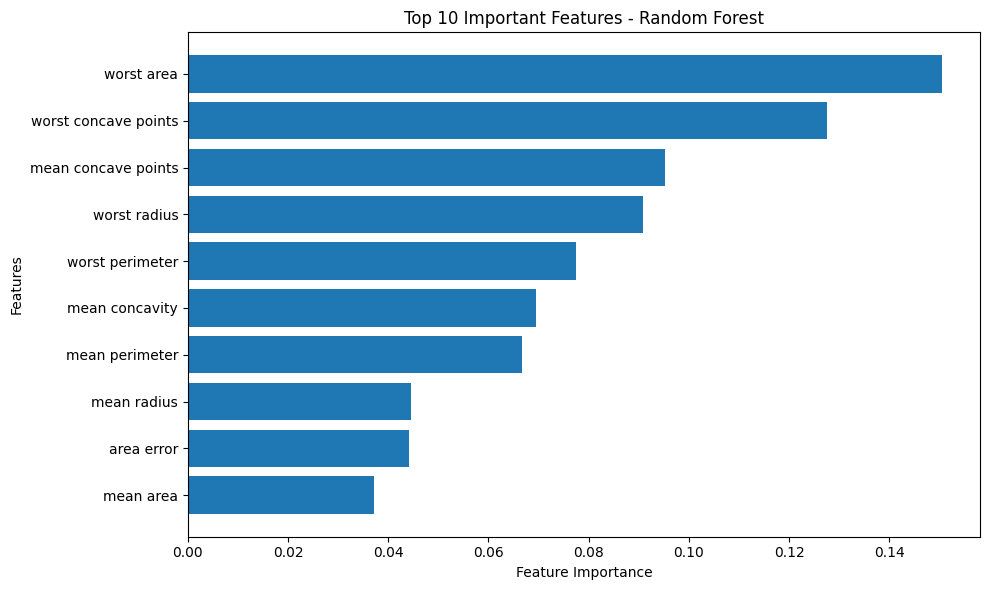

In [16]:
top_features = importance.head(10).sort_values(by="importance")

plt.figure(figsize=(10, 6))
plt.barh(top_features["Feature"], top_features["importance"])
plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Top 10 Important Features - Random Forest")
plt.tight_layout()
display(plt.gcf())


## 6. Visualizing Feature Importance

The horizontal bar chart displays the ten highest feature-importance scores from the table above.

- **`top_features`:** selects the ten highest-ranked features and sorts them for display.
- **`plt.barh()`:** draws a horizontal bar for each feature.
- **Axis labels and title:** identify the feature names and importance scores.
- **`tight_layout()` and `show()`:** improve spacing and display the figure.

Longer bars represent larger impurity-based importance scores. The chart helps compare the relative scores, but it does not establish causation and can be affected by correlations among features.

## 7. Interpreting Feature Importance, Correlation, and Permutation Importance

### What the highest-ranked features represent

In the refreshed impurity-importance table, the top features are `worst area` (**0.1506**), `worst concave points` (**0.1275**), `mean concave points` (**0.0953**), `worst radius` (**0.0908**), and `worst perimeter` (**0.0774**). Radius, perimeter, and area describe related aspects of cell-nucleus size. `Mean` measurements describe an average, while `worst` measurements generally describe the largest or most extreme measurement. Concavity and concave-point measurements describe indentation and shape along the nucleus boundary.

### Why radius, perimeter, and area can cluster together

Radius, perimeter, and area are related size measurements and are therefore strongly correlated. They often carry overlapping information about the nucleus. When several correlated features are available, a Random Forest can choose one feature for a split instead of another similar feature. As a result, importance can be shared across the group, and an individual feature may rank lower than expected even when the group is useful.

### Comparing impurity importance with permutation importance

`final_model.feature_importances_` measures impurity reduction accumulated across the fitted trees. `permutation_importance`, calculated on the held-out test set with accuracy as the scoring metric, shuffles one feature at a time and measures the resulting change in accuracy. A larger positive mean decrease indicates greater reliance on that feature for test-set accuracy under this test.

In the refreshed permutation output, `mean concave points` ranks first with a mean accuracy decrease of **0.004825**, followed by `worst texture` (**0.002193**) and `compactness error` (**0.000439**). Several other features have a mean decrease of **0.000000**, and `fractal dimension error` has a slightly negative mean (**-0.000439**). This differs from impurity importance, where `worst area` ranks first. The methods measure different things: impurity importance reflects tree splits, while permutation importance measures the test-score impact of shuffling a feature. Correlated features can substitute for one another, reducing the apparent impact of permuting only one feature. The permutation standard deviations also matter; small mean changes with relatively large variation are uncertain. Neither method demonstrates causation or provides a medical diagnosis.

                Feature  importance  Permutation Importance Mean  Permutation Importance Std
    mean concave points    0.095327                     0.004825                    0.007584
          worst texture    0.019937                     0.002193                    0.008717
      compactness error    0.006182                     0.000439                    0.001912
            mean radius    0.044556                     0.000000                    0.000000
worst fractal dimension    0.005289                     0.000000                    0.000000
              mean area    0.037214                     0.000000                    0.000000
   concave points error    0.003958                     0.000000                    0.000000
         symmetry error    0.003351                     0.000000                    0.000000
 mean fractal dimension    0.002949                     0.000000                    0.000000
fractal dimension error    0.003772                    -0.000439      

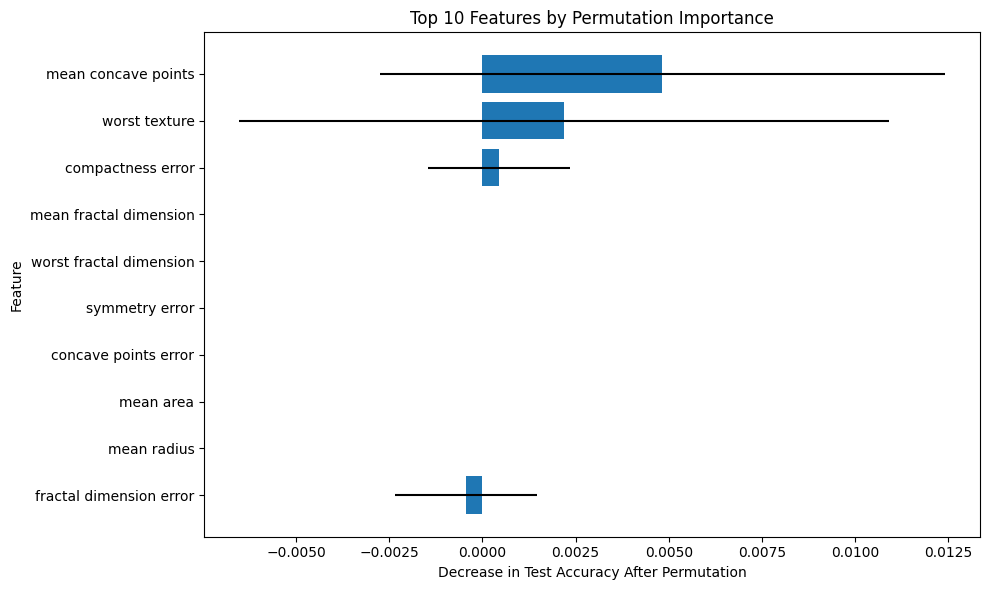

In [17]:
perm = permutation_importance(
    final_model,
    X_test,
    y_test,
    n_repeats=20,
    random_state=42,
    scoring="accuracy"
)

permutation_scores = pd.DataFrame({
    "Feature": X.columns,
    "Permutation Importance Mean": perm.importances_mean,
    "Permutation Importance Std": perm.importances_std
}).sort_values(
    by="Permutation Importance Mean",
    ascending=False
)

importance_comparison = importance.merge(
    permutation_scores,
    on="Feature",
    how="left"
).sort_values(
    by="Permutation Importance Mean",
    ascending=False
)

print(importance_comparison.head(10).to_string(index=False))

top_perm = importance_comparison.head(10).sort_values(
    by="Permutation Importance Mean"
)

plt.figure(figsize=(10, 6))
plt.barh(
    top_perm["Feature"],
    top_perm["Permutation Importance Mean"],
    xerr=top_perm["Permutation Importance Std"]
)
plt.xlabel("Decrease in Test Accuracy After Permutation")
plt.ylabel("Feature")
plt.title("Top 10 Features by Permutation Importance")
plt.tight_layout()
display(plt.gcf())


## 8. Confusion Matrix and Malignant-Class Recall

The confusion matrix uses rows for true labels and columns for predicted labels, ordered as class 0 (malignant) and class 1 (benign). The upper-right cell counts **false negatives**: actual malignant cases incorrectly predicted as benign. These are costly errors in a medical setting because a malignant case is missed.

In the refreshed final-model output:

- **39** malignant cases are correctly predicted as malignant.
- **3** malignant cases are predicted as benign (false negatives).
- **3** benign cases are predicted as malignant (false positives).
- **69** benign cases are correctly predicted as benign.

The matrix is `[[39, 3], [3, 69]]`, so malignant-class recall is **39 / (39 + 3) = 0.9286**. The value **0.9524** from the earlier saved manual comparison belonged to certain separate candidate models; it was not the final selected model's recall. The refreshed manual table and final-model evaluation should each be read as results for the models they actually describe.

Recall for class 0 is important because it measures the proportion of actual malignant cases correctly identified. Overall test accuracy is **0.9474**, but accuracy alone can hide missed malignant cases. This model is an educational exercise, not a clinically validated diagnostic system.

Malignant-class recall = 0.9286


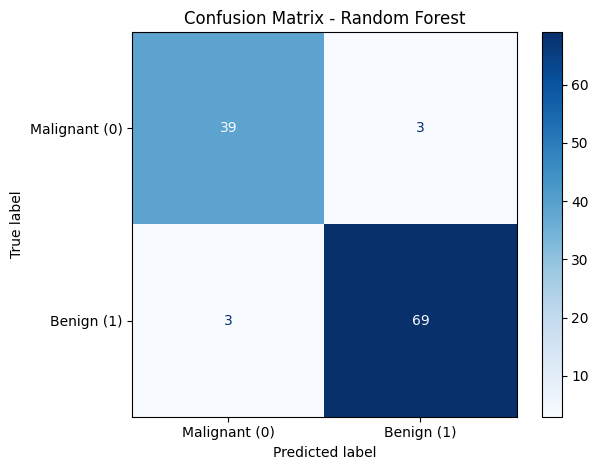

In [18]:
cm = confusion_matrix(y_test, y_prec, labels=[0, 1])
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Malignant (0)", "Benign (1)"]
)
disp.plot(cmap="Blues")
plt.title("Confusion Matrix - Random Forest")
plt.tight_layout()
display(plt.gcf())

malignant_recall = recall_score(y_test, y_prec, pos_label=0)
print("Malignant-class recall =", round(malignant_recall, 4))


## 9. Conclusion

This notebook classifies breast tumors as malignant (target 0) or benign (target 1) using a Random Forest model. Five-fold stratified `GridSearchCV` selected `n_estimators=100`, `max_depth=10`, `max_features='sqrt'`, `min_samples_split=2`, and `min_samples_leaf=1`, with a best mean cross-validation `recall_macro` of **0.9642**. The selected settings were then fitted on the full training split.

The final model achieved **1.0000 training accuracy** and **0.9474 test accuracy**, a train/test gap of **0.0526** (about 5.26 percentage points). This gap indicates that the model fits the training data better than the held-out test data, so some overfitting is present. In the final confusion matrix `[[39, 3], [3, 69]]`, three malignant cases were predicted as benign, and malignant-class recall was **0.9286**. The earlier value **0.9524** belonged to certain candidate models in the manual comparison table, not to the final selected model; after rerunning, the current manual table reports **0.9286** for its displayed candidates.

The two importance methods give complementary views. Impurity importance ranks `worst area` first (**0.1506**), while test-set permutation importance ranks `mean concave points` first by mean decrease in accuracy (**0.004825**). Radius, perimeter, and area are correlated size measurements, so their individual impurity importance can be distributed across related features and the rankings can differ between methods.

Because false negatives are costly in a medical setting, malignant-class recall deserves particular attention rather than relying on accuracy alone. The model is for educational analysis only and is not a clinically validated diagnostic system.